# HW4 - Notebook 4: Final test (Apr 1, 2016 – Sep 30, 2026)

Use the chosen model and trading rules from Notebooks 2–3 to run once on the test period and compared with
\$1,000,000 in `^SP500TR` bought at the first test close.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
import sys, warnings
%matplotlib inline

# Course setup
course_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
modeling_dir = course_root / 'Lectures/modeling'
if str(modeling_dir) not in sys.path:
    sys.path.insert(0, str(modeling_dir))

from data import experiment
from features import PANEL_PATH
from model import investable, walk_forward, yearly_fit_dates, candidates, FINAL_MODEL, TOP_N
from backtester import (plan_picks, load_price_matrix, run_backtest, check_accounting,
                        benchmark_values, performance)

START, END = experiment['test_start'], experiment['test_end']
RF = experiment['risk_free_hurdle']

## 1. Score the test period
We pick stocks using prices up to Mar 31, 2016, and buy them the next trading day on Apr 1. Each year the model is “refreshed” using only past trades whose 90 days have already ended. Since the factor score always uses the same fixed formula, the refresh doesn’t actually change anything. It only proves that no future information is used.

In [ ]:
# Score every buyable stock each month-end from Mar 2016 to Sep 2026 with the frozen model
panel = investable(pd.read_parquet(PANEL_PATH))
pipeline, features, target = candidates[FINAL_MODEL]
scores, audit = walk_forward(panel, pipeline, features, target,
                             yearly_fit_dates(panel, experiment['buffer_end'], END), end=END)
display(audit)

,fit_date,training_rows,last_finished_outcome,scores_signals,scored_rows
0,2016-03-31,104783,2016-02-29,2016-03-31 .. 2016-12-30,17892
1,2017-01-31,124375,2017-01-30,2017-01-31 .. 2017-12-29,22238
2,2018-01-31,146482,2018-01-30,2018-01-31 .. 2018-12-31,22641
3,2019-01-31,169085,2019-01-30,2019-01-31 .. 2019-12-31,22532
4,2020-01-31,191612,2020-01-30,2020-01-31 .. 2020-12-31,22394
5,2021-01-29,212163,2020-12-30,2021-01-29 .. 2021-12-31,22644
6,2022-01-31,234643,2021-12-30,2022-01-31 .. 2022-12-30,22587
7,2023-01-31,258823,2023-01-30,2023-01-31 .. 2023-12-29,22550
8,2024-01-31,281139,2024-01-30,2024-01-31 .. 2024-12-31,22654
9,2025-01-31,303515,2025-01-30,2025-01-31 .. 2025-12-31,22880


## 2. Run the backtest and audit it

In [ ]:
# Top 30 stocks at each month-end
picks = plan_picks(scores, TOP_N)
# load_data warns about 1 off-calendar price row, which it quarantines
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    prices, bench = load_price_matrix(np.concatenate(picks.values), end=END)

# main run
result = run_backtest(prices, picks, start=START, end=END)
# alternative run: stocks that stop trading are sold at their last price
alt = run_backtest(prices, picks, start=START, end=END, missing_exit='last_price')
print(f'{len(result.orders)} monthly batches, {len(result.lots):,} purchases; '
      f'exits: {result.lots.exit_type.value_counts().to_dict()}')
display(check_accounting(result, prices, END))

123 monthly batches, 3,690 purchases; exits: {'sell': 3573, 'open_at_end': 62, 'write_off': 55}


,passed
"value = cash + positions, every day",True
cash never negative,True
final cash = start - buys - fees + sale proceeds,True
each batch budget <= cash at its signal,True
every buy fills at the session after its signal,True
entry price = that day's adjusted close,True
every closed lot held >= 90 calendar days,True
sells happen at the first quote on/after maturity,True
exit price = that day's adjusted close,True
no trade or value after the end date,True


## 3. Performance vs. the S&P 500 total-return index
Sharpe uses a 2% annual risk-free rate.

In [ ]:
# check benchmark values 
bench_values = benchmark_values(bench, START, END)
metrics = pd.DataFrame({
    'Strategy (write-off at $0)': performance(result.history.value, RF),
    'Strategy (last price, sensitivity)': performance(alt.history.value, RF),
    'S&P 500 TR': performance(bench_values, RF)}).T
formats = {'final_value': '${:,.0f}', 'total_return': '{:.1%}', 'CAGR': '{:.2%}',
           'max_drawdown': '{:.1%}', 'annual_volatility': '{:.1%}', 'sharpe': '{:.2f}'}
display(pd.DataFrame({c: metrics[c].map(f.format) for c, f in formats.items()}))

,final_value,total_return,CAGR,max_drawdown,annual_volatility,sharpe
Strategy (write-off at $0),"$1,253,095",25.4%,2.18%,-38.8%,13.5%,0.08
"Strategy (last price, sensitivity)","$2,138,048",113.9%,7.51%,-26.7%,13.0%,0.47
S&P 500 TR,"$4,402,747",340.3%,15.17%,-33.8%,17.8%,0.77


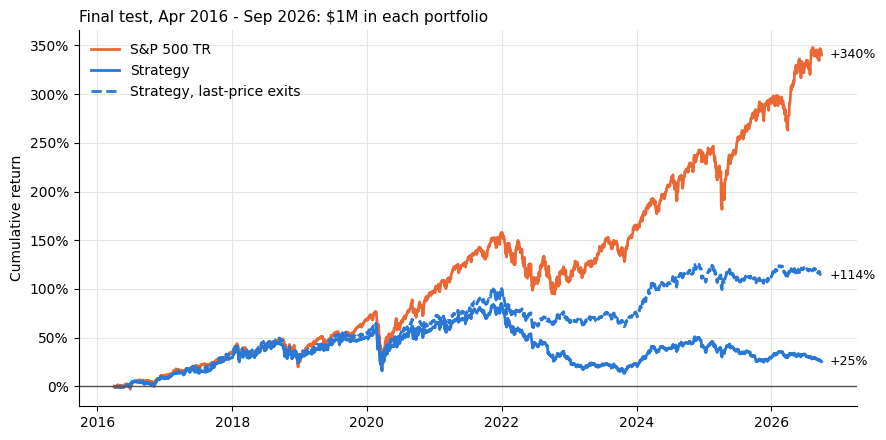

In [ ]:
# plotting to see difference betweeen my strategy and benchmark
fig, ax = plt.subplots(figsize=(9, 4.5))
series = [(bench_values, 'S&P 500 TR', '#eb6834', '-'),
          (result.history.value, 'Strategy', '#2a78d6', '-'),
          (alt.history.value, 'Strategy, last-price exits', '#2a78d6', '--')]
for values, label, color, style in series:
    growth = values / values.iloc[0] - 1
    ax.plot(growth.index, growth, color=color, ls=style, lw=2, label=label)
    ax.annotate(f'{growth.iloc[-1]:+.0%}', (growth.index[-1], growth.iloc[-1]), xytext=(6, 0),
                textcoords='offset points', va='center', fontsize=9)
ax.axhline(0, color='#52514e', lw=1)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_ylabel('Cumulative return')
ax.set_title('Final test, Apr 2016 - Sep 2026: $1M in each portfolio', loc='left', fontsize=11)
ax.legend(loc='upper left', frameon=False)
ax.grid(color='#e6e5e0')
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
fig.savefig('cumulative_return.png', dpi=150)   # saved next to the notebook for the README
plt.show()

In [ ]:
# Calendar year return comparisons
both = pd.DataFrame({'strategy': result.history.value, 'S&P 500 TR': bench_values})
yearly = pd.concat([both.iloc[[0]], both.resample('YE').last()]).pct_change().dropna()
yearly.index = yearly.index.year
display(yearly.assign(difference=yearly.strategy - yearly['S&P 500 TR']).round(3))

,strategy,S&P 500 TR,difference
date,,,
2016,0.076,0.098,-0.021
2017,0.200,0.218,-0.018
2018,-0.002,-0.044,0.042
2019,0.165,0.315,-0.149
2020,0.070,0.184,-0.114
2021,0.147,0.287,-0.140
2022,-0.306,-0.181,-0.125
2023,-0.038,0.263,-0.301
2024,0.131,0.250,-0.120


## 4. Why the strategy lagged
Three checks separate stock selection from the portfolio rules.

In [ ]:
lots = result.lots
# keep only purchases that have ended
closed = lots[lots.exit_type != 'open_at_end'].copy()
b = bench.reindex(prices.index)
closed['sp_same_window'] = [b[x] / b[e] - 1 for e, x in zip(closed.entry_date, closed.exit_date)]

# 1. did the top 30 we chose beat the average screened stock over the same 90 days?
scored = scores.merge(panel[['date', 'symbol', 'target', 'target_excess']], on=['date', 'symbol'])
top = scored.sort_values(['date', 'score'], ascending=[True, False]).groupby('date').head(TOP_N)
ic = scored.dropna(subset=['target']).groupby('date')[['score', 'target']].apply(
    lambda g: g.score.corr(g.target, method='spearman'))

# 2. Write-offs: lots with no quote within 5 sessions of maturity
written_off = lots[lots.exit_type == 'write_off']
display(pd.Series({
    'test rank IC (mean of months)': round(ic.mean(), 3),
    'top-30 mean 90-day return minus average screened stock': round(top.target_excess.mean(), 4),
    'mean 90-day lot return, after fees': round(closed.return_net.mean(), 4),
    'mean S&P 500 TR return over the same 90 days': round(closed.sp_same_window.mean(), 4),
    'write-offs (lots / stocks)': f'{len(written_off)} / {written_off.symbol.nunique()}',
    'cost of written-off lots': f'${written_off.cost.sum():,.0f}',
    'average share of the portfolio in cash': round((result.history.cash / result.history.value).mean(), 3),
}, name='value').to_frame())

,value
test rank IC (mean of months),0.045
top-30 mean 90-day return minus average screened stock,0.0002
"mean 90-day lot return, after fees",0.0117
mean S&P 500 TR return over the same 90 days,0.038
write-offs (lots / stocks),55 / 32
cost of written-off lots,"$730,158"
average share of the portfolio in cash,0.21


In [ ]:
# For written-off stocks, mostly acquisitions paid in cash, which the database does not record
display(written_off.groupby('symbol').agg(lots=('lot_id', 'size'), cost=('cost', 'sum'),
                                          first_due=('due_date', 'min')).sort_values('cost', ascending=False).head(10).round(0))
# Largest gains, checked for data errors
display(lots.nlargest(5, 'return_net')[['symbol', 'entry_date', 'exit_date', 'entry_price', 'exit_price', 'return_net']].round(3))

,lots,cost,first_due
symbol,,,
CERN,3,50433.0,2022-06-30
SAFM,3,48830.0,2022-07-31
CSGS,3,43983.0,2026-05-31
VIACP,2,39921.0,2022-03-01
ALXN,2,37483.0,2021-08-01
WPF,2,37442.0,2021-08-30
PSB,2,32066.0,2022-08-30
CDK,2,32066.0,2022-08-30
TGI,2,30910.0,2025-08-31


,symbol,entry_date,exit_date,entry_price,exit_price,return_net
734,WWE,2018-04-02,2018-07-02,33.51,71.86,1.140
1621,FRHC,2020-10-01,2020-12-30,24.32,51.67,1.120
762,WWE,2018-05-01,2018-07-30,38.14,75.43,0.974
2839,VST,2024-03-01,2024-05-30,54.04,104.85,0.936
1665,FRHC,2020-11-02,2021-02-01,27.33,51.82,0.892


## 5. Findings

- **The strategy did not beat the benchmark.** \$1M grew to about **\$1.25M** (CAGR ≈ 2.2%, Sharpe ≈ 0.08), against
  **\$4.40M** for the S&P 500 TR (CAGR ≈ 15.2%, Sharpe ≈ 0.77). It also had a deeper max drawdown.
- **Selection was roughly neutral.** The rank IC stayed positive (≈ +0.045, close to development), but the top 30 earned about the same as the average screened stock. The average screened stock trailed the cap-weighted index, which was led by mega-cap tech.
- **Write-offs cost the most.** 55 lots in 32 stocks lost their quotes. Most were cash takeovers (e.g. ALXN, CERN), which the database does not record, so they are written off at \$0 as the assignment requires. Selling at the last price instead gives about \$2.14M, still well below the index.
- **Cash drag.** Batches that start at month-end and mature about 90 days later are often sold just after the next signal, so the cash waits a month and some months are skipped. On average about 21% of the portfolio was in cash.
